In [3]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_colwidth", 120)

In [4]:
os.listdir("../data/raw")

['Musical_instruments_reviews.csv']

In [5]:
df = pd.read_csv("../data/raw/Musical_instruments_reviews.csv")

df.shape

(10261, 9)

In [5]:
df.head()

,reviewerID,asin,reviewerName,helpful,reviewText,overall,summary,unixReviewTime,reviewTime
0,A2IBPI20UZIR0U,1384719342,"cassandra tu ""Yeah, well, that's just like, u...","[0, 0]","Not much to write about here, but it does exactly what it's supposed to. filters out the pop sounds. now my recordin...",5.0,good,1393545600,"02 28, 2014"
1,A14VAT5EAX3D9S,1384719342,Jake,"[13, 14]",The product does exactly as it should and is quite affordable.I did not realized it was double screened until it arr...,5.0,Jake,1363392000,"03 16, 2013"
2,A195EZSQDW3E21,1384719342,"Rick Bennette ""Rick Bennette""","[1, 1]","The primary job of this device is to block the breath that would otherwise produce a popping sound, while allowing y...",5.0,It Does The Job Well,1377648000,"08 28, 2013"
3,A2C00NNG1ZQQG2,1384719342,"RustyBill ""Sunday Rocker""","[0, 0]",Nice windscreen protects my MXL mic and prevents pops. Only thing is that the gooseneck is only marginally able to h...,5.0,GOOD WINDSCREEN FOR THE MONEY,1392336000,"02 14, 2014"
4,A94QU4C90B1AX,1384719342,SEAN MASLANKA,"[0, 0]",This pop filter is great. It looks and performs like a studio filter. If you're recording vocals this will eliminate...,5.0,No more pops when I record my vocals.,1392940800,"02 21, 2014"


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10261 entries, 0 to 10260
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   reviewerID      10261 non-null  str    
 1   asin            10261 non-null  str    
 2   reviewerName    10234 non-null  str    
 3   helpful         10261 non-null  str    
 4   reviewText      10254 non-null  str    
 5   overall         10261 non-null  float64
 6   summary         10261 non-null  str    
 7   unixReviewTime  10261 non-null  int64  
 8   reviewTime      10261 non-null  str    
dtypes: float64(1), int64(1), str(7)
memory usage: 6.2 MB


In [7]:
df["overall"].value_counts().sort_index()

overall
1.0     217
2.0     250
3.0     772
4.0    2084
5.0    6938
Name: count, dtype: int64

In [8]:
df.isna().sum()

reviewerID         0
asin               0
reviewerName      27
helpful            0
reviewText         7
overall            0
summary            0
unixReviewTime     0
reviewTime         0
dtype: int64

In [6]:
df = df.dropna(subset=["reviewText"]).copy()

df.shape

(10254, 9)

In [7]:
print("exact duplicates:", df.duplicated().sum())
print("same person, product and text:", df.duplicated(subset=["reviewerID", "asin", "reviewText"]).sum())

df = df.drop_duplicates(subset=["reviewerID", "asin", "reviewText"]).copy()

df.shape

exact duplicates: 0
same person, product and text: 0


(10254, 9)

In [8]:
df["helpful_votes"] = df["helpful"].str.strip("[]").str.split(",").str[0].astype(int)
df["total_votes"] = df["helpful"].str.strip("[]").str.split(",").str[1].astype(int)

df = df.drop(columns=["helpful"])

df[["helpful_votes", "total_votes"]].head()

,helpful_votes,total_votes
0,0,0
1,13,14
2,1,1
3,0,0
4,0,0


In [9]:
df["review_date"] = pd.to_datetime(df["unixReviewTime"], unit="s")

print(df["review_date"].min(), "->", df["review_date"].max())

2004-09-18 00:00:00 -> 2014-07-22 00:00:00


In [10]:
df = df.drop(columns=["reviewerName", "summary"])

df.columns

Index(['reviewerID', 'asin', 'reviewText', 'overall', 'unixReviewTime',
       'reviewTime', 'helpful_votes', 'total_votes', 'review_date'],
      dtype='str')

In [11]:
def map_sentiment(rating):
    if rating <= 2:
        return "negative"
    elif rating == 3:
        return "neutral"
    else:
        return "positive"

df["sentiment"] = df["overall"].apply(map_sentiment)

df["sentiment"].value_counts()

sentiment
positive    9015
neutral      772
negative     467
Name: count, dtype: int64

In [12]:
pd.crosstab(df["overall"], df["sentiment"])

sentiment,negative,neutral,positive
overall,,,
1.0,217,0,0
2.0,250,0,0
3.0,0,772,0
4.0,0,0,2083
5.0,0,0,6932


In [13]:
df.to_csv("../data/processed/reviews_clean.csv", index=False)

print("saved:", df.shape[0], "rows,", df.shape[1], "columns")

saved: 10254 rows, 10 columns


In [14]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

sentiment_colors = {"negative": "#d9534f", "neutral": "#f0ad4e", "positive": "#5cb85c"}

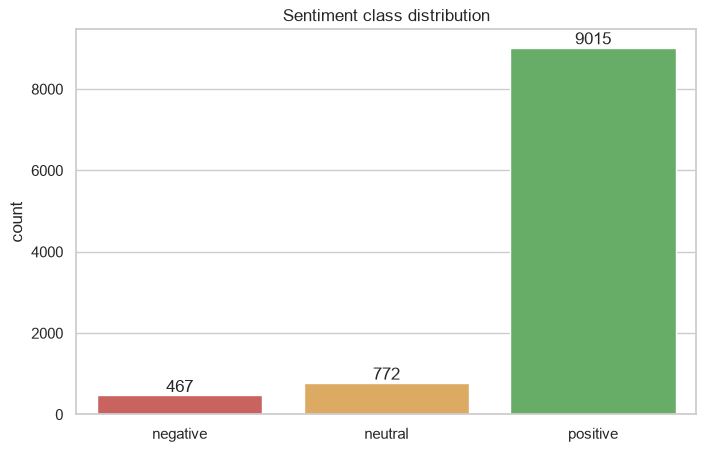

In [15]:
ax = sns.countplot(
    data=df, x="sentiment", hue="sentiment", legend=False,
    order=["negative", "neutral", "positive"], palette=sentiment_colors,
)
for container in ax.containers:
    ax.bar_label(container)

plt.title("Sentiment class distribution")
plt.xlabel("")
plt.savefig("../plots/sentiment_distribution.png", dpi=150)
plt.show()

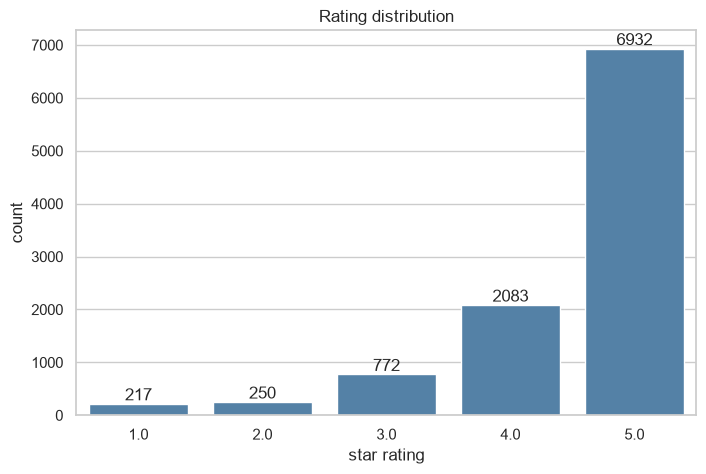

In [17]:
ax = sns.countplot(data=df, x="overall", color="steelblue")
for container in ax.containers:
    ax.bar_label(container)

plt.title("Rating distribution")
plt.xlabel("star rating")
plt.savefig("../plots/rating_distribution.png", dpi=150)
plt.show()

In [18]:
df["review_words"] = df["reviewText"].str.split().str.len()

df["review_words"].describe()

count    10254.000000
mean        90.244880
std        111.249566
min          1.000000
25%         31.000000
50%         54.000000
75%        104.000000
max       2043.000000
Name: review_words, dtype: float64

In [19]:
df.groupby("sentiment")["review_words"].median()

sentiment
negative    70.0
neutral     67.0
positive    52.0
Name: review_words, dtype: float64

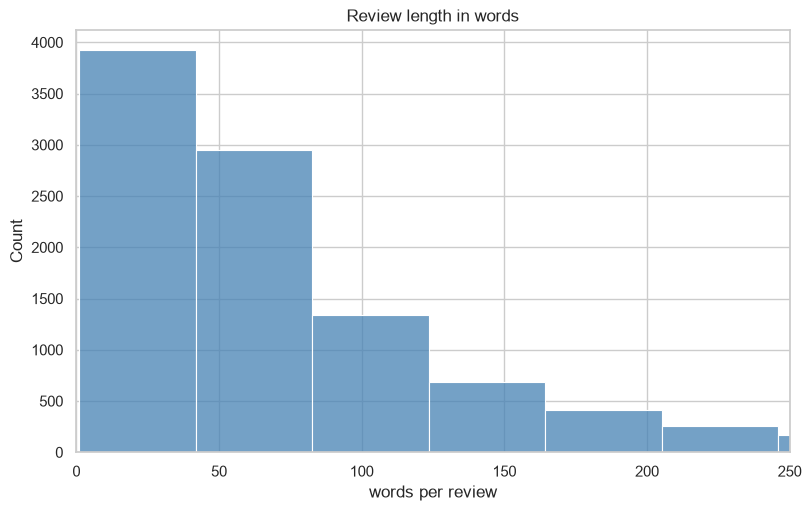

In [20]:
plt.figure(figsize=(8, 5), constrained_layout=True)
sns.histplot(data=df, x="review_words", bins=50, color="steelblue")

plt.xlim(0, 250)
plt.title("Review length in words")
plt.xlabel("words per review")
plt.savefig("../plots/review_length_histogram.png", dpi=150)
plt.show()

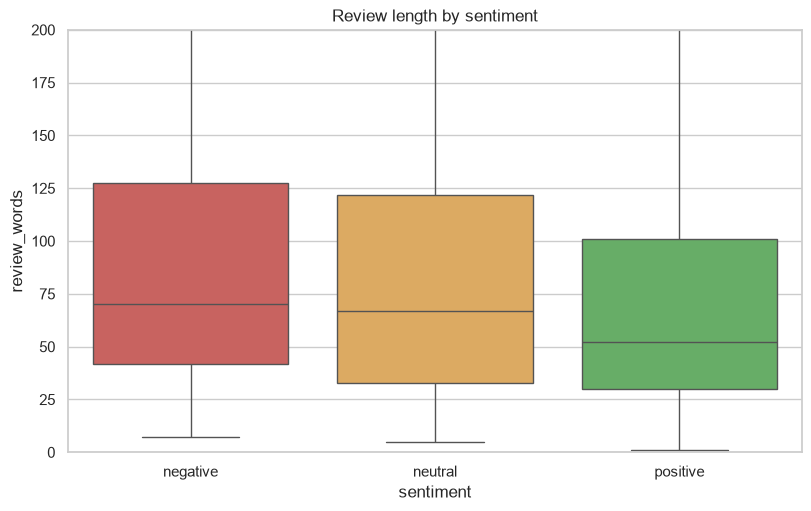

In [21]:
plt.figure(figsize=(8, 5), constrained_layout=True)
sns.boxplot(
    data=df, x="sentiment", y="review_words", hue="sentiment", legend=False,
    order=["negative", "neutral", "positive"], palette=sentiment_colors,
)

plt.ylim(0, 200)
plt.title("Review length by sentiment")
plt.savefig("../plots/length_by_sentiment.png", dpi=150)
plt.show()

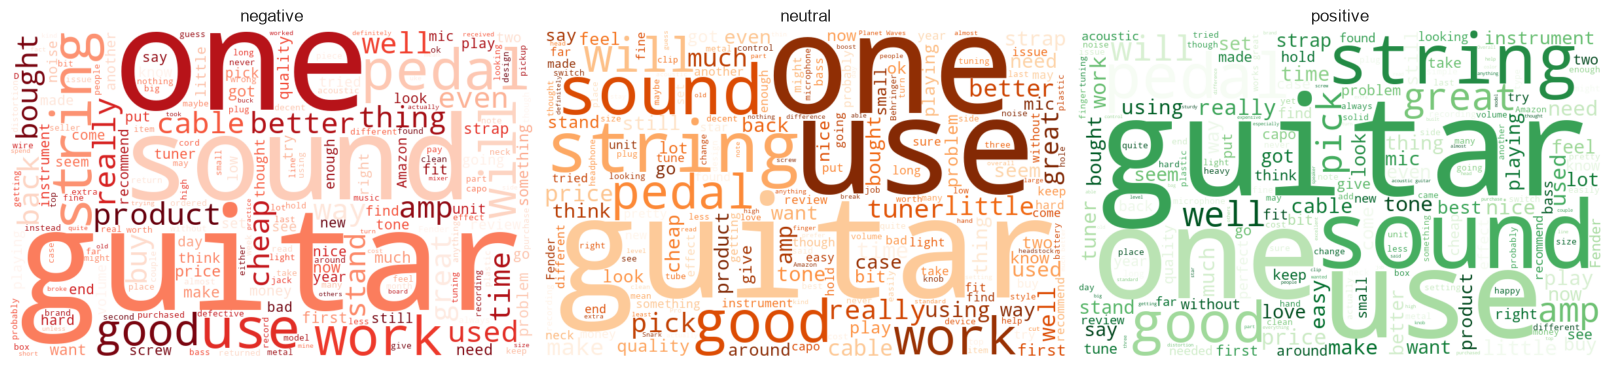

In [22]:
from wordcloud import WordCloud, STOPWORDS

cmaps = {"negative": "Reds", "neutral": "Oranges", "positive": "Greens"}

fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)

for ax, sentiment in zip(axes, ["negative", "neutral", "positive"]):
    text = " ".join(df.loc[df["sentiment"] == sentiment, "reviewText"])
    wc = WordCloud(
        width=800, height=500, background_color="white",
        stopwords=set(STOPWORDS), colormap=cmaps[sentiment],
    ).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(sentiment)
    ax.axis("off")

plt.savefig("../plots/wordclouds_by_sentiment.png", dpi=150)
plt.show()

In [23]:
import re
from collections import Counter

stop_words = set(STOPWORDS)

def class_tokens(sentiment):
    text = " ".join(df.loc[df["sentiment"] == sentiment, "reviewText"]).lower()
    tokens = re.findall(r"[a-z]+", text)
    return [t for t in tokens if t not in stop_words and len(t) > 2]

tokens_by_class = {s: class_tokens(s) for s in ["negative", "neutral", "positive"]}

Counter(tokens_by_class["negative"]).most_common(15)

[('one', 276),
 ('guitar', 250),
 ('sound', 176),
 ('use', 159),
 ('good', 143),
 ('pedal', 142),
 ('will', 140),
 ('don', 122),
 ('strings', 117),
 ('work', 114),
 ('really', 113),
 ('better', 110),
 ('back', 101),
 ('amp', 100),
 ('used', 99)]

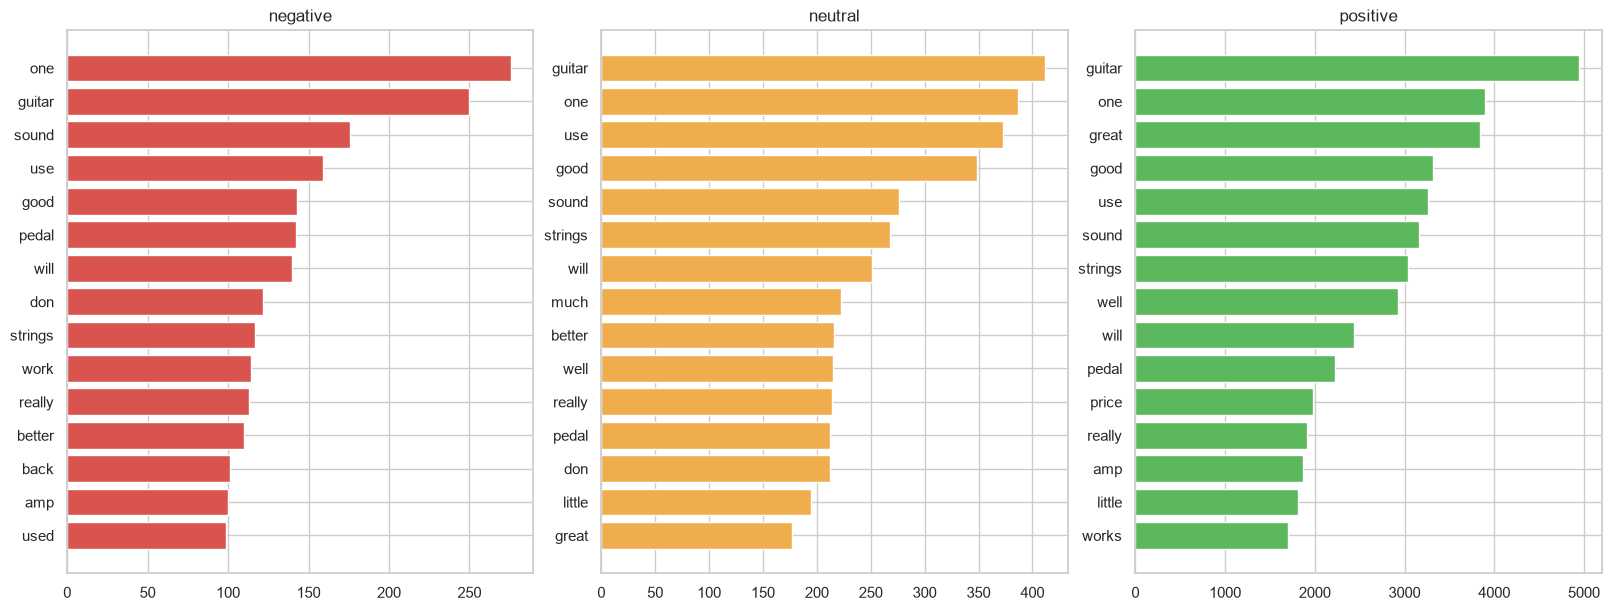

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)

for ax, sentiment in zip(axes, ["negative", "neutral", "positive"]):
    words, counts = zip(*Counter(tokens_by_class[sentiment]).most_common(15))
    ax.barh(range(len(words)), counts, color=sentiment_colors[sentiment])
    ax.set_yticks(range(len(words)))
    ax.set_yticklabels(words)
    ax.invert_yaxis()
    ax.set_title(sentiment)

plt.savefig("../plots/top_words_by_sentiment.png", dpi=150)
plt.show()

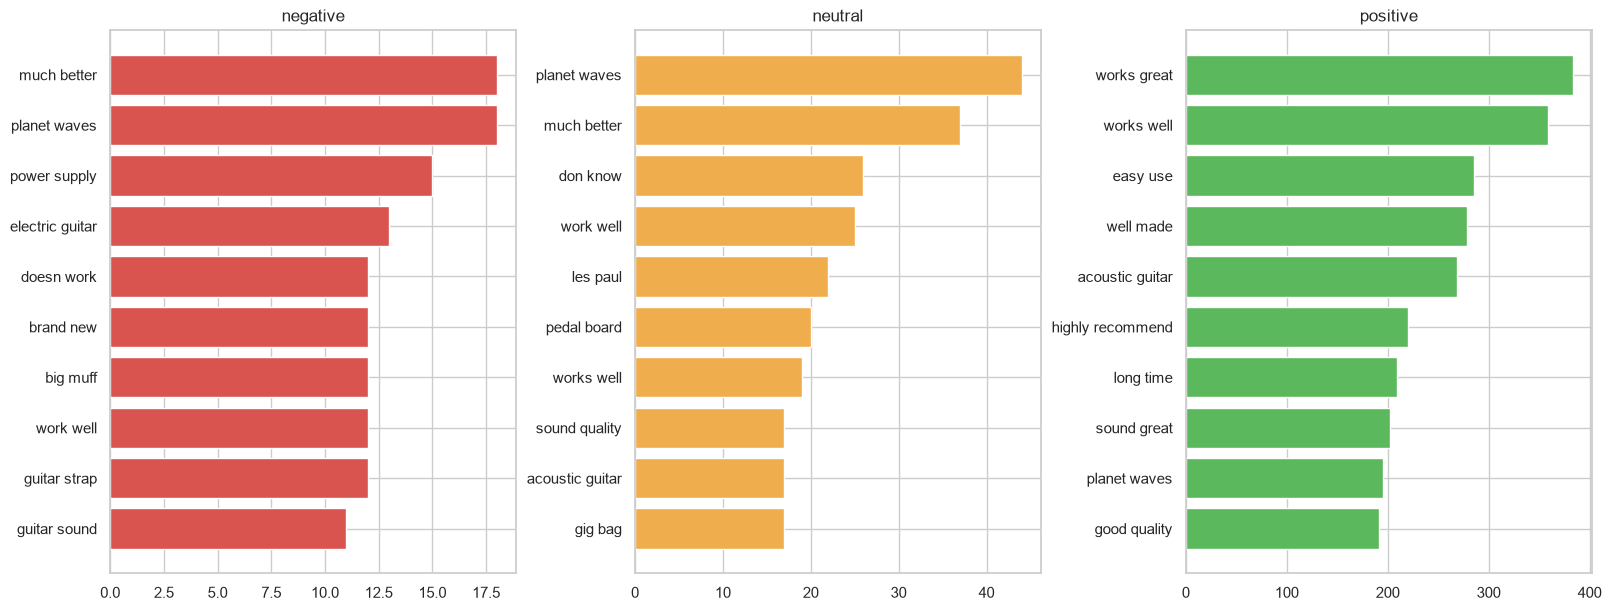

In [25]:
def top_bigrams(sentiment, n=10):
    return Counter(zip(tokens_by_class[sentiment], tokens_by_class[sentiment][1:])).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)

for ax, sentiment in zip(axes, ["negative", "neutral", "positive"]):
    pairs, counts = zip(*top_bigrams(sentiment))
    labels = [" ".join(p) for p in pairs]
    ax.barh(range(len(labels)), counts, color=sentiment_colors[sentiment])
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.set_title(sentiment)

plt.savefig("../plots/top_bigrams_by_sentiment.png", dpi=150)
plt.show()

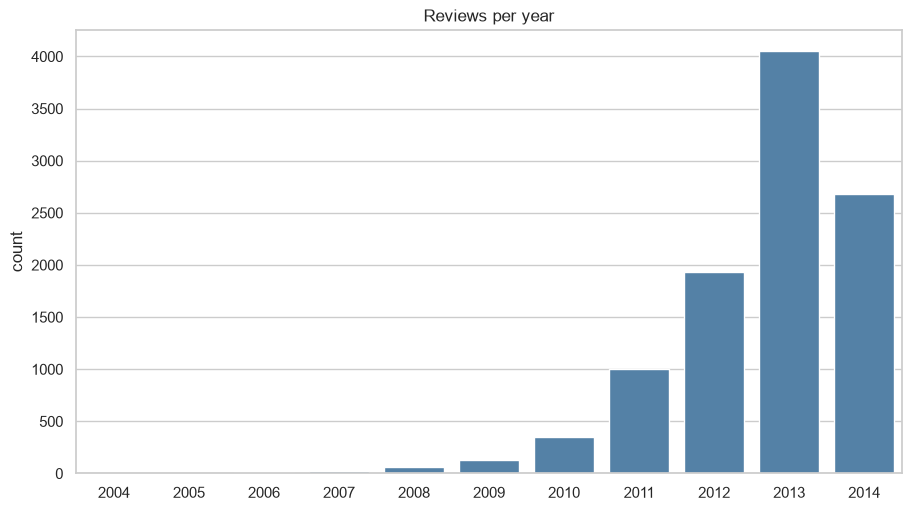

In [26]:
df["review_year"] = df["review_date"].dt.year

plt.figure(figsize=(9, 5), constrained_layout=True)
sns.countplot(data=df, x="review_year", color="steelblue")

plt.title("Reviews per year")
plt.xlabel("")
plt.savefig("../plots/reviews_per_year.png", dpi=150)
plt.show()

In [27]:
df.groupby("sentiment")["helpful_votes"].mean()

sentiment
negative    2.032120
neutral     1.941710
positive    1.477759
Name: helpful_votes, dtype: float64

In [34]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

stop_words = set(stopwords.words("english"))

# we deliberately KEEP negations - they flip the meaning of a review
negations = {"no", "not", "nor", "never"}
stop_words = stop_words - negations

print(len(stop_words), "stopwords loaded")

195 stopwords loaded


In [35]:
contractions = {
    "don't": "do not", "doesn't": "does not", "didn't": "did not",
    "can't": "cannot", "won't": "will not", "isn't": "is not",
    "wasn't": "was not", "aren't": "are not", "couldn't": "could not",
    "wouldn't": "would not", "shouldn't": "should not",
    "haven't": "have not", "hasn't": "has not", "hadn't": "had not",
    "it's": "it is", "i'm": "i am", "i've": "i have", "i'd": "i would",
    "that's": "that is", "there's": "there is", "what's": "what is",
    "let's": "let us", "you're": "you are", "they're": "they are",
}

def preprocess_text(text):
    text = text.lower()
    for short, full in contractions.items():
        text = text.replace(short, full)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = nltk.word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)

In [36]:
test_sentences = [
    "This pedal sounds AMAZING! I've been using it for 6 months.",
    "It doesn't work at all. Total waste of money, returning it.",
    "Not bad for the price, but the cable feels cheap.",
]

for s in test_sentences:
    print("BEFORE:", s)
    print("AFTER: ", preprocess_text(s))
    print()

BEFORE: This pedal sounds AMAZING! I've been using it for 6 months.


NameError: name 'nltk' is not defined